# Notebook 09: Search as an Indivisible Process

**Goal:** Read Grover's search algorithm (Nielsen & Chuang ch. 6) as an indivisible stochastic process on the
database indices, and find where its speedup lives in Barandes's terms.

By the end of this notebook you will be able to:
- Show that a phase oracle is invisible to Γ, that the marked item first appears in Γ through indivisibility across two queries,
  and why the standard bit oracle, which Γ can see, does not change the picture
- Show that the speedup needs a query-free preparation step, and that search from a bare configuration does worse than classical search
- Show that Grover's search moves the probability column along a geodesic on the probability sphere
- Measure how records (division events) during the search erode the √N speedup, and why with full records a longer search does worse
- Check that Farhi–Gutmann continuous-time search approaches the speed limit $T \ge \arccos(1/\sqrt N)/\nu$, with ν read off Γ, and see that
  a diagonal term leaves ν unchanged but lets the column move faster than ν, so the bound's premise belongs to this Hamiltonian,
  not to every process with the same ν

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Study copy of `09_search_as_isp.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-10-23 from the Grover spike (`notes/grover-as-isp-spike-2026-10-23.md`) after reading
> Nielsen & Chuang ch. 6, to answer two questions: *do records during a search erode the √N speedup?* and
> *is the speed limit of notebook 07 tight for search?* Short answers: yes, once the total record strength
> ε√N reaches order 1; and, for the Farhi–Gutmann Hamiltonian, yes asymptotically, in the form $T \ge \arccos(1/\sqrt N)/\nu$.
> That bound is not a Γ-only law: a diagonal term leaves ν unchanged but lets the column move faster than ν (end of section 5).
>
> **Prior work (checked 2026-10-29, corrected 2026-11-05).** The ε√N scale matches Shenvi, Brown & Whaley (2003, §II: oracle phase error
> $O(N^{-1/4})$, i.e. coherence loss $\sim N^{-1/2}$ per query). Search from a bare configuration is covered by Biham et al. (1999), and the
> geodesic by Miyake and Wadati (2001) and Alvarez and Gómez (1999, preprint). The arccos speed limit is Mandelstam–Tamm for the start $|s\rangle$.
> The invisibility of the phase oracle and the Γ-only query bound restate standard results in Γ language. Details in the 🔭 cell at the end.
>
> The copy also covers the phase-oracle vs. bit-oracle distinction (section 1), the result of the Γ-only query-bound spike
> (`notes/gamma-only-query-bound-spike-2026-10-23.md`, section 5), and, right after this banner, a summary of what Γ explains
> about the search and what it doesn't.
---

### 📖 In depth: what Γ explains about Grover search, and what it doesn't

A summary of this notebook and the two follow-up spikes (`notes/gamma-only-query-bound-spike-2026-10-23.md`,
`notes/margolus-levitin-gamma-spike-2026-10-23.md`). Short version: **Γ explains how the search works and why it is
fragile; by the standard proof route, it does not explain why it cannot go faster.**

**What Γ explains**
- **Where the answer lives.** A query writes the answer as a phase, which Γ cannot see. The answer reaches the probabilities
  only through interference between successive queries, i.e. through indivisibility (section 1). With the bit oracle the query
  itself is Γ-visible, but the useful information still travels through phases Γ does not record.
- **Why preparation matters.** From a single index the queries do worse than a classical searcher (at most $1/(N-1)$ against $k/N$); the query-free
  Walsh–Hadamard step is what lets them steer (section 2).
- **The route and the √N count.** The probability column takes the shortest path on the probability sphere from uniform to $e_w$,
  at a fixed $2\theta = 2\arcsin(1/\sqrt N)$ per query (N&C's θ). Distance about $\pi/2$ divided by that step gives about $\tfrac{\pi}{4}\sqrt N$ queries (section 3). In
  continuous time it is distance ÷ speed, with the speed ν read off Γ in frequency units (section 5); that last step holds for the
  Farhi–Gutmann Hamiltonian, not for every Hamiltonian with the same ν.
- **Why records kill it.** Recording the index erases the interference that carries the answer. With full records the oracle
  drops out of the process and searching longer makes things worse; the record strength per query must stay below about $1/\sqrt N$ (section 4).

**What Γ does not explain**
- **Why it can't go faster.** The √N lower bound can be *stated* in Γ, and its counting step is pure Γ, but the standard (hybrid-argument) proof
  needs the unitary dilation, and no Γ-only proof is known: the query-free steps can push the two runs' probabilities apart by amounts Γ does not determine.
- **Why the diffusion step is the right one.** Its effect depends on phases: 20,000 steps with exactly Grover's Γ gave from 15%
  to 67% of Grover's progress on the first step.
- **Which energy-based speed limits apply.** For a real Hamiltonian such as this one, Γ cannot tell $H$ from its time-reversed twin $-H$
  (in general Γ(H) = Γ(−H*), since $e^{iH^*t}$ is the complex conjugate of $e^{-iHt}$; compare Barandes's remark after Paper 3
  eq. 89 that complex conjugation is "just a change of phases"), so neither Margolus–Levitin nor its
  dual (Ness, Alberti & Sagi, PRL 2022) can be stated in Γ, even in symmetric combination (notebook 07). In their orthogonality form neither applies
  to search, because the search state never becomes orthogonal to its start. A non-orthogonal generalization exists (Giovannetti,
  Lloyd & Maccone 2003, "Quantum limits to dynamical evolution", Phys. Rev. A 67, 052109), but for search its energy scale is close to ν anyway.
- **Whether the speed limit is general.** It is not. The bound that matters is the energy spread of the starting state, which Γ does not
  supply; for Farhi–Gutmann it happens to equal ν. A diagonal term leaves ν unchanged and lets the column move about twice as fast (end of section 5).

**Net.** Mechanism, route and fragility live at the level of Γ. Optimality, and even the speed limit, live one level down, in the phases and
energies. That is the same pattern as notebook 07: ν comes from Γ (in frequency units, where ħ is absorbed), but one Hilbert-space step is borrowed.

<!-- expansion:09:before-start -->
### 🧭 Before you start

**What this notebook is for.** Grover's algorithm finds one marked item among $N$ using about $\tfrac{\pi}{4}\sqrt N$ queries,
where a classical search needs order $N$. This notebook asks where that advantage lives when the computer is described Barandes's
way: always in one definite configuration (a database index), moving between configurations with probabilities Γ that are
*indivisible*, i.e. not built from step-by-step transition matrices.

**Prerequisites.**
- Notebook 05: indivisibility, and "the interference fringes *are* the divisibility defect".
- Notebook 06: records and division events.
- Notebook 07: the probability sphere, the Bhattacharyya angle, the agility ν and the speed limits written in Γ (Mandelstam–Tamm in Γ form).
- Notebook 08: records as phase damping, CP-divisible at every strength.
- No prior knowledge of Grover's algorithm; the 📚 cells summarize Nielsen & Chuang (N&C) ch. 6.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*, or step through with Shift+Enter. The first code cell
adds the folder one level up to `sys.path` and imports `unitary_to_transition_matrix` from `isp/quantum.py`, so `isp/` must sit next to
`notebooks/`. Only numpy, scipy and matplotlib are needed. Section 4 takes the longest: it evolves $N\times N$ density matrices up to
$N = 1024$ for six noise strengths, then again for its second plot.

**Search-engineer framing.** The oracle is a relevance judge that can confirm "this is the document" but never returns a score
you can sort by. How can a procedure still home in faster than checking documents one at a time?


<!-- expansion:09:glossary -->
### 📘 Glossary

- **Configuration.** The definite state at any moment: a database index $0,\dots,N-1$ (plus an ancilla bit for the bit oracle).
- **Γ.** $\Gamma_{ij}$ = probability of being at $i$ later given $j$ now. For a unitary, $\Gamma_{ij} = |U_{ij}|^2$ ("unistochastic").
- **Indivisible (at $t'$).** No stochastic $\Gamma(t\leftarrow t')$ satisfies $\Gamma(t\leftarrow 0) = \Gamma(t\leftarrow t')\,\Gamma(t'\leftarrow 0)$. Checking whether Γ over two steps equals the product of the one-step Γs is the weaker "matched" test (notebook 05).
- **Record / division event.** An environment notes the configuration; afterwards Γ factorizes at that time.
- **Oracle, query.** The black box that recognizes the answer; one use is one query. Search cost is counted in queries (**query complexity**).
- **Phase oracle.** $O = I - 2|w\rangle\langle w|$: a $-1$ on the marked index. No probability changes.
- **Bit oracle.** $|x, b\rangle \mapsto |x, b \oplus f(x)\rangle$: flips a helper bit (the **ancilla**) when $x$ is the answer. A reversible classical "is this it?".
- **Phase kickback.** With the ancilla in $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$, the bit flip becomes a $-1$ on the index: bit oracle → phase oracle.
- **Walsh–Hadamard $W = H^{\otimes n}$.** A Hadamard on each of $n$ qubits ($N = 2^n$); takes $|0\rangle$ to the uniform $|s\rangle$. No query.
- **Diffusion $D = 2|s\rangle\langle s| - I$.** "Inversion about the mean", $a_k \mapsto 2\bar a - a_k$. No query. One **Grover iterate** is $G = DO$.
- **θ.** $\arcsin(1/\sqrt N)$: the angle between $|s\rangle$ and the uniform superposition of the unmarked indices. One Grover iterate rotates by $2\theta$. N&C's θ is the full rotation per iteration ($\cos(\theta/2) = \sqrt{(N-M)/N}$), i.e. $2\times$ this notebook's θ.
- **Amplitude amplification.** The standard generalization of Grover's iterate to any preparation and any set of marked items. Background knowledge, not taken from the on-disk sources and not developed here.
- **Probability sphere.** A distribution $p$ drawn as the unit vector $\sqrt p$.
- **Bhattacharyya angle.** $\arccos\sum_i\sqrt{p_i q_i}$: the great-circle angle between $\sqrt p$ and $\sqrt q$. A **geodesic** is a shortest path, here a great-circle arc.
- **Hellinger distance.** $h = \|\sqrt p - \sqrt q\|$: the straight-line chord between the same two points.
- **Phase damping ε.** Partial record: off-diagonals of ρ multiplied by $1-\varepsilon$, diagonal untouched. $\varepsilon = 1$ is a full record.
- **Farhi–Gutmann search.** Continuous-time search with $H = |w\rangle\langle w| + |s\rangle\langle s|$, run for time $\pi\sqrt N/2$.
- **Agility ν.** Notebook 07's Γ-only speed, $\nu_j = \sqrt{-\tfrac12\ddot\Gamma_{jj}(0)}$: how fast the probability of staying at $j$ starts to fall.
- **Mandelstam–Tamm, Margolus–Levitin.** Quantum speed limits set by the energy spread (MT) or the mean energy above the ground state (ML).
- **Unitary dilation.** Writing Γ as $|U_{ij}|^2$ of an underlying unitary: the one Hilbert-space step this notebook borrows.
- **BBBV, hybrid argument.** Bennett–Bernstein–Brassard–Vazirani's proof that search needs order $\sqrt N$ queries, by comparing runs with and without the oracle.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.quantum import unitary_to_transition_matrix as Gam

### 📖 In depth: search, in Barandes's language

- **The configurations are the database positions.** At any moment the system "is at" one index; Γ gives the probability of
  moving between indices.
- **A query marks the answer by a phase**, a minus sign on $w$. A phase is pure Hilbert-space bookkeeping: it changes no probability,
  so Γ cannot see it.
- **So how does the answer get found?** The sign changes how later steps combine. Two paths that lead to the same index either
  reinforce or cancel depending on the sign they picked up. In Γ terms, that is exactly a failure of divisibility: the two-step
  transition matrix is not the product of the one-step ones (and here, more strongly, no stochastic matrix at all takes the
  one-query Γ to the two-query Γ).
- **For a search engineer.** It is a ranking procedure in which the relevance signal is never a score you can read directly;
  it only shows up in how successive re-weightings interfere. Read out the ranking after every step (a record) and the signal is lost.

<!-- expansion:09:papers-barandes -->
### 📚 From the papers: Γ from a unitary, and division events (Barandes)

From `barandes1_stochastic_quantum_correspondence.txt`:
- §3.4 "Unistochastic processes", eq. (30): $\Gamma_{ij}(t \leftarrow 0) = |U_{ij}(t \leftarrow 0)|^2$, a "unistochastic matrix", one "whose individual entries are the
  modulus-squares of the corresponding entries of a unitary matrix". `Gam` in the code is this map.
- §3.7 "Division events and the Markov approximation", around eq. (56): after contact with an environment the transition matrix is
  "manifestly divisible at $t'$", and "it is therefore natural to refer to the new conditioning time $t'$ as a division event." Section 4's records are these.


<!-- expansion:09:papers-nc-oracle -->
### 📚 From the papers: the oracle and the procedure (N&C §6.1.1–6.1.2)

- **N&C's oracle is a bit oracle** (eq. 6.1): $|x\rangle|q\rangle \to |x\rangle|q \oplus f(x)\rangle$, where "the oracle qubit $|q\rangle$ is a single qubit which is flipped if $f(x) = 1$".
- **Phase kickback** (eqs. 6.2–6.3): with the oracle qubit in $(|0\rangle - |1\rangle)/\sqrt2$ the action becomes $|x\rangle \to (-1)^{f(x)}|x\rangle$, and the oracle qubit
  "can therefore be omitted from further discussion". The oracle "marks the solutions … by shifting the phase of the solution."
- **Recognizing is not knowing.** N&C stress "a distinction between knowing the solution to a search problem, and being able to
  recognize the solution". In search terms: the oracle is a verifier, not an index.
- **The procedure** (§6.1.2): $H^{\otimes n}$ on $|0\rangle^{\otimes n}$ gives the uniform state (eq. 6.4); then repeat the Grover iteration: oracle, $H^{\otimes n}$, a phase
  shift on every basis state except $|0\rangle$, $H^{\otimes n}$. The last three combine to $2|\psi\rangle\langle\psi| - I$ (eq. 6.6), "inversion about mean" (Exercise 6.2, eq. 6.7).

N&C's $|\psi\rangle$ is this notebook's $|s\rangle$ and their $2|\psi\rangle\langle\psi| - I$ is $D$. Only the oracle sees $w$.


## 1. The Oracle Is Invisible to Γ

Configurations are the $N$ database indices; one of them, $w$, is marked. Grover's iterate is $G = D\,O$ with

$$O = I - 2|w\rangle\langle w|, \qquad D = 2|s\rangle\langle s| - I, \qquad |s\rangle = \tfrac{1}{\sqrt N}\textstyle\sum_j |j\rangle .$$

Every unitary $U$ defines the transition matrix $\Gamma(U)_{ij} = |U_{ij}|^2$. The oracle only flips a sign, so $\Gamma(O) = I$.
One full query from a configuration is also blind to $w$: $|(DO)_{ij}| = |D_{ij}|$, so $\Gamma(DO) = \Gamma(D)$.
Started from a configuration, the marked item enters Γ only after two queries, and only because $\Gamma((DO)^2) \neq \Gamma(DO)\,\Gamma(DO)$: through indivisibility.
With the Walsh–Hadamard step $W$ first (section 2) it appears after one query, since $\Gamma(DOW) \neq X\,\Gamma(W)$ for every stochastic $X$
($\Gamma(W)$ has identical columns, $\Gamma(DOW)$ does not): again through indivisibility.

This depends on the encoding. The standard **bit oracle** $|x, b\rangle \mapsto |x, b \oplus [x = w]\rangle$, with an ancilla bit as part of the configuration,
is a permutation that depends on $w$, so Γ sees it. Grover turns it into the phase oracle by preparing the ancilla in $|-\rangle$.

In [2]:
def grover_ops(N, w):
    s = np.full(N, 1 / np.sqrt(N))
    O = np.eye(N); O[w, w] = -1
    D = 2 * np.outer(s, s) - np.eye(N)
    return O, D, s


N = 16
O, D, s = grover_ops(N, 0)
print(f'N = {N}:  max |Γ(O) − I| = {np.abs(Gam(O) - np.eye(N)).max():.1e}')
for k in (1, 2, 3):
    Gk = {w: Gam(np.linalg.matrix_power(grover_ops(N, w)[1] @ grover_ops(N, w)[0], k)) for w in range(N)}
    spread = max(np.abs(Gk[w] - Gk[0]).max() for w in range(N))
    divisible_guess = np.linalg.matrix_power(Gam(D @ O), k)
    print(f'k = {k} queries:  max over w of |Γ((DO)^k)[w] − Γ((DO)^k)[0]| = {spread:.4f}'
          f'   |Γ((DO)^k) − Γ(DO)^k| = {np.abs(Gk[0] - divisible_guess).max():.4f}')

G2 = Gam(np.linalg.matrix_power(D @ O, 2))
B = np.eye(2 * N)
B[[0, 1]] = B[[1, 0]]                                        # bit oracle for w = 0, configurations (x, b) -> 2x + b
print(f'bit oracle:  Γ(B) is a permutation that moves {int((np.diag(Gam(B)) < 0.5).sum())} configurations, (w,0) <-> (w,1)')

print(f'\nTwo queries from configuration 1:  Γ(w=0 ← 1) = {G2[0, 1]:.4f}   Γ(other ← 1) = {G2[2, 1]:.4f}'
      f'   ratio = {G2[0, 1] / G2[2, 1]:.0f}   Γ(1 ← 1) = {G2[1, 1]:.4f}')

N = 16:  max |Γ(O) − I| = 0.0e+00
k = 1 queries:  max over w of |Γ((DO)^k)[w] − Γ((DO)^k)[0]| = 0.0000   |Γ((DO)^k) − Γ(DO)^k| = 0.0000
k = 2 queries:  max over w of |Γ((DO)^k)[w] − Γ((DO)^k)[0]| = 0.6562   |Γ((DO)^k) − Γ(DO)^k| = 0.3486
k = 3 queries:  max over w of |Γ((DO)^k)[w] − Γ((DO)^k)[0]| = 0.8613   |Γ((DO)^k) − Γ(DO)^k| = 0.4550
bit oracle:  Γ(B) is a permutation that moves 2 configurations, (w,0) <-> (w,1)

Two queries from configuration 1:  Γ(w=0 ← 1) = 0.0479   Γ(other ← 1) = 0.0010   ratio = 49   Γ(1 ← 1) = 0.9385


### 🔍 Reading the code

- **`Gam`** is `unitary_to_transition_matrix` from `isp/quantum.py`: entrywise $|U_{ij}|^2$, the same map as notebooks 03, 04 and 07.
- **`grover_ops(N, w)`** returns the oracle $O$, the diffusion $D$ and the uniform vector $s$ as plain matrices.
- **The k-loop** builds $\Gamma((DO)^k)$ for every possible marked item $w$ and reports how much it changes with $w$ (zero means "Γ cannot
  tell which item is marked"), and how far it is from the divisible guess $\Gamma(DO)^k$.
- **`B`** is the bit oracle on $2N$ configurations (index, ancilla bit), ordered $(x, b) \to 2x + b$. For $w = 0$ it swaps rows 0 and 1:
  a permutation, which Γ sees.
- **The last line** shows where the information goes after two queries. From a bare configuration most of the probability
  stays put (Γ(1 ← 1) is large), but of what moves, the transition into $w$ is dozens of times larger than into any other index.
  The answer is now visible in Γ; it is still small, because no preparation was done (section 2).

<!-- expansion:09:howto-sec1 -->
### 🧭 How to use this cell / what to look at

**What it computes.** For $N = 16$: Γ of the oracle; Γ of $(DO)^k$ for $k = 1, 2, 3$ and every possible marked item; the bit oracle's Γ;
and the two-query transition probabilities out of configuration 1.

**What to look at.**
- `max |Γ(O) − I| = 0.0e+00`: the oracle moves no probability.
- $k = 1$: both columns `0.0000`. One query cannot tell which item is marked.
- $k = 2$: the spread over $w$ jumps to `0.6562` and the divisibility defect to `0.3486`. The marked item appears in Γ exactly when Γ stops being a product.
- Bit oracle: `moves 2 configurations`, the Γ-visible swap of $(w,0)$ and $(w,1)$.
- Last line: `Γ(w=0 ← 1) = 0.0479` against `0.0010`, `ratio = 49`. Visible but weak: `Γ(1 ← 1) = 0.9385` never moved.

**Try this.**
1. Set `N = 64`. Prediction (derivation below): ratio $((N-2)/2)^2 = 961$; the $k = 1$ line stays zero.
2. Print `Gam(D)[:3, :3]`. Prediction: off-diagonals $4/N^2$, diagonal $(1-2/N)^2$, no $w$ anywhere.


<!-- expansion:09:deriv-two-query -->
### 🧮 Worked derivation: the factor 49 after two queries

Write $d = 2/N$, so $D_{ij} = d - \delta_{ij}$. Start in configuration $j = 1$, with $w = 0$.

1. First iterate. $O e_1 = e_1$, then $D e_1$ has entries $d$ everywhere except $d - 1$ at index 1.
2. Second query. $O$ flips index 0: $v = (-d,\; d-1,\; d,\dots,d)$, with sum $\Sigma = -d + (d-1) + (N-2)d = 1 - 4/N$.
3. Second diffusion. $(Dv)_i = d\,\Sigma - v_i$:
   - into $w$: $d\Sigma + d = d(2 - 4/N)$;
   - into another index: $d\Sigma - d = -4d/N$;
   - staying at 1: $1 - 4d/N$.
4. Square. For $N = 16$ ($d = 1/8$): $0.21875^2 = 0.0479$, $0.03125^2 = 0.0010$, $0.96875^2 = 0.9385$, the printed numbers.
   The ratio is $\big((2 - 4/N)/(4/N)\big)^2 = \big((N-2)/2\big)^2 = 49$.

The single minus sign at index 0 survives into Σ and then *adds* to the amplitude flowing into $w$. A divisible chain squares
each step first, $\sum_k \Gamma(D)_{ik}\Gamma(D)_{k1}$, which contains no sign and therefore no $w$.


### 📖 In depth: why one query is blind and two are not

$O$ is diagonal with entries $\pm 1$, so $(DO)_{ij} = D_{ij}\,o_j$ and $|(DO)_{ij}|^2 = |D_{ij}|^2$. One query from a definite configuration
changes no probability.

Two queries: $\big((DO)^2\big)_{ij} = \sum_k D_{ik}\, o_k\, D_{kj}\, o_j$. The sum runs over intermediate indices $k$, and the sign $o_k$ flips the
contribution of the path through $k = w$. Squaring the sum produces cross terms between paths: interference. A divisible process
would instead add the squared path weights, $\sum_k |D_{ik}|^2 |D_{kj}|^2$, in which every $o_k$ has disappeared.

So the marked item is encoded in the cross terms, the part of $\Gamma((DO)^2)$ that a product of one-step Γs cannot reproduce. This is
notebook 05's "the fringes ARE the divisibility defect", applied to search.

### 📖 In depth: phase oracle vs. bit oracle

"The oracle is invisible to Γ" depends on what counts as a configuration.

- **Phase oracle**, configurations = indices only: the query is a sign, $\Gamma(O) = I$. Invisible.
- **Bit oracle**, configurations = (index, ancilla bit): $|x, b\rangle \mapsto |x, b\oplus[x=w]\rangle$ is a permutation that swaps $(w,0)$ and $(w,1)$.
  Γ sees it: this is exactly a classical query. Grover converts it into the phase oracle by preparing the ancilla in $|-\rangle$
  (phase kickback); the sign then lives in a superposition of ancilla configurations.

So the encoding-independent statement is not about the query. It is about the **query-free steps**: in both encodings the
speedup comes from what $D$ (or any other query-free step) does with phase information that Γ does not record. The 📖 cell on
the Γ-only query bound in section 5 makes that precise.

<!-- expansion:09:recap-sec1 -->
### 📝 Recap: section 1

- $\Gamma(O) = I$ and $\Gamma(DO) = \Gamma(D)$: one phase-oracle query from a configuration leaves no trace in Γ.
- After two queries $w$ is visible (ratio 49 at $N = 16$), exactly when $\Gamma((DO)^2) \ne \Gamma(DO)^2$: the information sits in cross terms between paths.
- With the bit oracle the query is Γ-visible; what stays hidden is the phase bookkeeping the query-free steps exploit.


## 2. The Speedup Needs a Preparation Step

Start in configuration $0$. The circuit applies the Walsh–Hadamard transform $W = H^{\otimes n}$ (no query) and then
$k$ Grover iterates, so the process is $\Gamma(G^k W)$ and the success probability is $\Gamma_{w \leftarrow 0}(G^k W)$.
Without $W$ the same queries act on a bare configuration. The fair baseline is a classical searcher, who checks one index per query
and after $k$ queries has found $w$ with probability $k/N$.

The code uses $\theta = \arcsin(1/\sqrt N)$, the angle between $|s\rangle$ and the uniform superposition of the unmarked indices.
Each Grover iterate rotates the state by $2\theta$, and the success probability after $k$ iterates is $\sin^2((2k+1)\theta)$.
Nielsen & Chuang use θ for the full rotation per iteration, defined by $\cos(\theta/2) = \sqrt{(N-M)/N}$ (§6.1.3), so this
notebook's θ is their $\theta/2$ (with $M = 1$ marked item), and their "rotation by θ" is this notebook's $2\theta$ per query.

N = 64, marked item 37, k* = 6
with preparation:  Γ(w ← 0) at k* = 0.9966   (sin²((2k*+1)θ) = 0.9966)
bare configuration: max over k of Γ(w ← 0) = 0.0158   (× N = 1.01;  1/(N−1) = 0.0159)
classical search, checking k* = 6 indices: finds w with probability k*/N = 0.0938


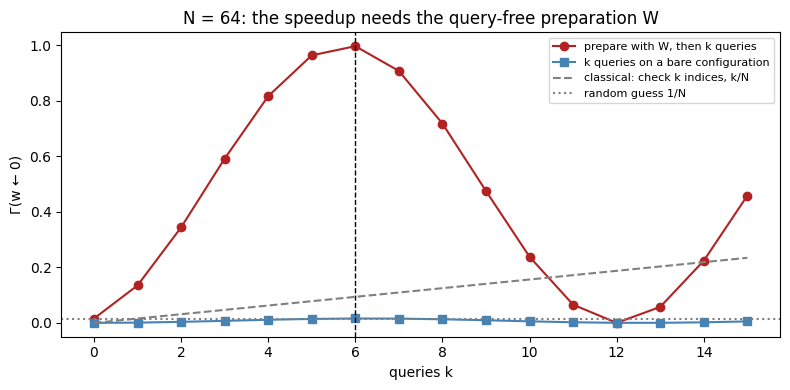

In [3]:
n = 6
N = 2 ** n
w = 37
Hd = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
W = Hd
for _ in range(n - 1):
    W = np.kron(W, Hd)
O, D, s = grover_ops(N, w)
G = D @ O
theta = np.arcsin(1 / np.sqrt(N))
k_star = int(round(np.pi / (4 * theta) - 0.5))

ks = np.arange(0, 16)
P_prep = [Gam(np.linalg.matrix_power(G, k) @ W)[w, 0] for k in ks]
P_bare = [Gam(np.linalg.matrix_power(G, k))[w, 0] for k in ks]
print(f'N = {N}, marked item {w}, k* = {k_star}')
print(f'with preparation:  Γ(w ← 0) at k* = {P_prep[k_star]:.4f}   (sin²((2k*+1)θ) = {np.sin((2 * k_star + 1) * theta) ** 2:.4f})')
print(f'bare configuration: max over k of Γ(w ← 0) = {max(P_bare):.4f}   (× N = {max(P_bare) * N:.2f};  1/(N−1) = {1 / (N - 1):.4f})')
print(f'classical search, checking k* = {k_star} indices: finds w with probability k*/N = {k_star / N:.4f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, P_prep, 'o-', color='firebrick', label='prepare with W, then k queries')
ax.plot(ks, P_bare, 's-', color='steelblue', label='k queries on a bare configuration')
ax.plot(ks, ks / N, '--', color='gray', label='classical: check k indices, k/N')
ax.axhline(1 / N, color='gray', ls=':', label='random guess 1/N')
ax.axvline(k_star, color='black', ls='--', lw=1)
ax.set_xlabel('queries k'); ax.set_ylabel('Γ(w ← 0)')
ax.set_title(f'N = {N}: the speedup needs the query-free preparation W')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

<!-- expansion:09:howto-sec2 -->
### 🧭 How to use this cell / what to look at

**What it computes.** For $N = 64$, marked item 37: the probability of ending at $w$ from configuration 0 after $k = 0,\dots,15$ queries,
with the Walsh–Hadamard preparation (red) and without it (blue).

**What to look at.**
- `k* = 6`, from $\mathrm{round}(\pi/(4\theta) - \tfrac12)$ with $\sin\theta = 1/8$ (derivation below).
- `Γ(w ← 0) at k* = 0.9966`, equal to `sin²((2k*+1)θ) = 0.9966`: the stochastic description reproduces the textbook success probability.
- Red curve: near 1 at $k^*$, then falls. Grover overshoots; it is periodic, not monotone.
- Blue curve: stuck near the dotted $1/N$ line (`× N = 1.01`; the printed ceiling $1/(N-1)$), far below the dashed classical line $k/N$.

**Try this.**
1. Change `w`. Prediction: identical numbers; nothing depends on which index is marked.
2. Set `n = 2` ($N = 4$) and `w` to an index below 4 (index 37 no longer exists). Prediction: $\theta = \pi/6$ (N&C's θ is $\pi/3$), $k^* = 1$,
   success exactly 1 (N&C Box 6.1).
3. Set `n = 10` and widen `ks` to cover $k^*$, e.g. `np.arange(0, 40)` (with 16 values the lookup `P_prep[k_star]` fails). Prediction: $k^* = 25$,
   success 0.9995, bare-configuration `× N` = 1.00. Slower: it raises $1024\times1024$ matrices to powers.


### 📖 In depth: why the preparation step matters

$W$ uses no query, and $\Gamma(W)$ is the uniform matrix: from configuration 0 it sends you to every index with probability $1/N$. As a
classical step it is useless (a uniform random restart). As a quantum step it creates $|s\rangle$, the state from which every path to $w$
starts with the same phase, so that Grover's sign flips can steer them.

Without $W$, the queries act on a single index. Most paths stay near the start, and the transition into $w$ never rises above
$1/(N-1)$ (the printout: $N \cdot \max_k \Gamma_{w\leftarrow 0} = 1.01$). A classical searcher checking one index per query would by then have found $w$
with probability $k^*/N$, about six times more at $N = 64$: without the preparation, quantum search is worse than classical. In Barandes's terms, the process is indivisible at the end of $W$:
$\Gamma(W)$ is rank-one uniform and $\Gamma(G^kW)$ is not, so no stochastic step maps one to the other. Recording the index there would make
it a division event and destroy the speedup.

<!-- expansion:09:papers-nc-geometry -->
### 📚 From the papers: the geometric picture and the iteration count (N&C §6.1.3–6.1.4)

- **Two reflections make a rotation** (§6.1.3, Figure 6.3). With $|\alpha\rangle$ the uniform superposition of non-solutions (eq. 6.8) and $|\beta\rangle$ that of
  solutions (eq. 6.9), "the oracle operation O performs a reflection about the vector $|\alpha\rangle$", $2|\psi\rangle\langle\psi| - I$ "also performs a reflection … about the vector
  $|\psi\rangle$. And the product of two reflections is a rotation!" After $k$ iterations (eq. 6.12) the state is
  $\cos\big(\tfrac{2k+1}{2}\theta\big)|\alpha\rangle + \sin\big(\tfrac{2k+1}{2}\theta\big)|\beta\rangle$.
- **Iteration count** (§6.1.4): $R = \mathrm{CI}\big(\arccos\sqrt{M/N}/\theta\big)$ (eq. 6.15), bounded by $R \le \tfrac{\pi}{4}\sqrt{N/M}$ (eq. 6.17),
  "a quadratic improvement over the $O(N/M)$ oracle calls required classically."
- **$N = 4$** (Box 6.1): "only exactly one iteration is required", while a classical computer "would require on average 2.25 oracle queries".

**Notation.** N&C's θ is the full rotation per iteration: they set $\cos(\theta/2) = \sqrt{(N-M)/N}$ and conclude "the rotation angle is in
fact θ" (§6.1.3, eq. 6.11). This notebook's θ is $\arcsin(1/\sqrt N)$, which is N&C's $\theta/2$ for $M = 1$. N&C's "rotation by θ" is this
notebook's "2θ per query", and their $\tfrac{2k+1}{2}\theta$ in eq. 6.12 is this notebook's $(2k+1)\theta$.


<!-- expansion:09:deriv-rotation -->
### 🧮 Worked derivation: the iterate as a rotation by 2θ, and $k^* \approx \tfrac{\pi}{4}\sqrt N$

Let $|r\rangle$ be the uniform superposition of the $N-1$ unmarked indices. Then

$$|s\rangle = \tfrac{1}{\sqrt N}|w\rangle + \sqrt{\tfrac{N-1}{N}}\,|r\rangle = \sin\theta\,|w\rangle + \cos\theta\,|r\rangle, \qquad \sin\theta = \tfrac{1}{\sqrt N}.$$

1. **$O$ reflects about $|r\rangle$**: $a|r\rangle + b|w\rangle \mapsto a|r\rangle - b|w\rangle$.
2. **$D$ reflects about $|s\rangle$**: it keeps the $|s\rangle$ component and negates the perpendicular one.
3. **Two reflections about lines θ apart make a rotation by 2θ** (N&C's rotation angle θ). So
   $$G^k|s\rangle = \sin\big((2k+1)\theta\big)\,|w\rangle + \cos\big((2k+1)\theta\big)\,|r\rangle, \qquad P_w(k) = \sin^2\big((2k+1)\theta\big).$$
4. **Best k.** $P_w = 1$ at $(2k+1)\theta = \pi/2$, i.e. $k = \pi/(4\theta) - \tfrac12$; rounding gives `k_star`. For $N = 64$: $\theta = 0.1253$, $5.77 \to 6$,
   so $(2k^*+1)\theta = 1.629$ lands just past $\pi/2$ and $P_w = \sin^2(1.629) = 0.9966$, the printed value.
5. **Large N.** $\theta \approx 1/\sqrt N$, so $k^* \approx \tfrac{\pi}{4}\sqrt N$.

**Why the bare start fails.** A single unmarked index overlaps the $\{|w\rangle, |r\rangle\}$ plane only by $1/\sqrt{N-1}$. Outside the plane
$O$ acts as $I$ and $D$ as $-I$, so that part just flips sign and stays put. $W$ puts the whole state into the plane.


<!-- expansion:09:recap-sec2 -->
### 📝 Recap: section 2

- With the query-free $W$ first, $\Gamma_{w\leftarrow 0}(G^kW) = \sin^2((2k+1)\theta)$: 0.9966 at $k^* = 6$ for $N = 64$. Without $W$, worse than classical search: best at most $1/(N-1)$, against $k/N$ for a classical searcher after $k$ queries.
- As a stochastic step $\Gamma(W)$ is a useless uniform reshuffle; its value is entirely in the phases it sets up.


## 3. Grover's Search Is a Geodesic on the Probability Sphere

As in notebook 07, map each probability column $p$ to $\sqrt p$ on the unit sphere and measure distances by the
Bhattacharyya angle $\arccos\sum_i\sqrt{p_i q_i}$. Column 0 of $\Gamma(G^k W)$ starts at the uniform point and should end near $e_w$.

The evidence for the geodesic is the printed ratio *path length / direct angle*. The right-hand plot only displays the route: in
$(\sqrt{1-P_w}, \sqrt{P_w})$ coordinates every distribution lands on the unit circle, so the plot alone proves nothing.

N = 256, k* = 12:  path length / direct angle = 1.000000   step angle / 2θ = 1.000000 … 1.000000   Γ(w ← 0) at k* = 0.9999


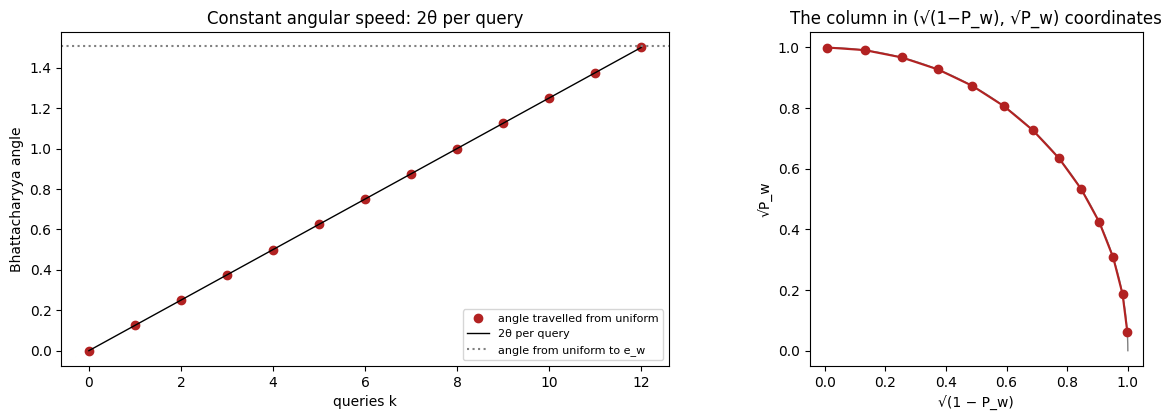

In [4]:
def bh_angle(p, q):
    return np.arccos(np.clip(np.sqrt(p) @ np.sqrt(q), -1, 1))


N = 256
O, D, s = grover_ops(N, 0)
theta = np.arcsin(1 / np.sqrt(N))
k_star = int(round(np.pi / (4 * theta) - 0.5))
psi, cols = s.copy(), [s ** 2]
for _ in range(k_star):
    psi = D @ (O @ psi)
    cols.append(psi ** 2)
steps = [bh_angle(cols[k], cols[k + 1]) for k in range(k_star)]
direct = bh_angle(cols[0], cols[-1])
print(f'N = {N}, k* = {k_star}:  path length / direct angle = {sum(steps) / direct:.6f}'
      f'   step angle / 2θ = {min(steps) / (2 * theta):.6f} … {max(steps) / (2 * theta):.6f}'
      f'   Γ(w ← 0) at k* = {cols[-1][0]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ks = np.arange(k_star + 1)
axes[0].plot(ks, [bh_angle(cols[0], c) for c in cols], 'o', color='firebrick', label='angle travelled from uniform')
axes[0].plot(ks, 2 * theta * ks, '-', color='black', lw=1, label='2θ per query')
axes[0].axhline(np.arccos(1 / np.sqrt(N)), color='gray', ls=':', label='angle from uniform to e_w')
axes[0].set_xlabel('queries k'); axes[0].set_ylabel('Bhattacharyya angle')
axes[0].set_title('Constant angular speed: 2θ per query')
axes[0].legend(fontsize=8)
arc = np.linspace(0, np.pi / 2, 200)
axes[1].plot(np.cos(arc), np.sin(arc), color='gray', lw=1)
axes[1].plot([np.sqrt(1 - c[0]) for c in cols], [np.sqrt(c[0]) for c in cols], 'o-', color='firebrick')
axes[1].set_xlabel('√(1 − P_w)'); axes[1].set_ylabel('√P_w'); axes[1].set_aspect('equal')
axes[1].set_title('The column in (√(1−P_w), √P_w) coordinates')
plt.tight_layout()
plt.show()

<!-- expansion:09:howto-sec3 -->
### 🧭 How to use this cell / what to look at

**What it computes.** For $N = 256$ ($k^* = 12$): the probability column after each query, each step's Bhattacharyya angle, and the
summed path compared with the direct angle.

**What to look at.**
- `path length / direct angle = 1.000000`: no detour, so the path is a geodesic.
- `step angle / 2θ = 1.000000 … 1.000000`: every step covers exactly the Hilbert-space rotation angle $2\theta$ (N&C's θ). At $N = 256$,
  $(2k^*+1)\theta = 1.5635$ stays below $\pi/2$, so no step overshoots.
- Left plot: dots on the line $2\theta k$, ending just under $\arccos(1/\sqrt N)$, the angle from uniform to $e_w$.
- Right plot: the column in coordinates $(\sqrt{1-P_w}, \sqrt{P_w})$, on the quarter circle. Every distribution lands on that circle in these coordinates, so the plot only shows the route; the geodesic evidence is the path/direct ratio above.

**Try this.**
1. Set `N = 1024`. Prediction: $k^* = 25$ and `path length / direct angle = 1.000000` still, but `step angle / 2θ = 0.257299 … 1.000000`,
   with `Γ(w ← 0) at k* = 0.9995`. Here $(2k^*+1)\theta = 1.594$ passes $\pi/2$: the last query carries the column through $e_w$ and a little
   way back along the same great circle, so its net angle is only about a quarter of $2\theta$. Path still equals direct because every
   point lies on that one arc.
2. Loop to `k_star + 3`. Prediction: unmarked amplitudes turn negative, $\sqrt p = |\psi|$ folds back toward uniform, and the path exceeds
   the direct angle (ratio 1.63 at $N = 256$).


### 📖 In depth: why the path is a geodesic

Grover's iterate is a rotation by $2\theta$ in the plane spanned by $|w\rangle$ and the uniform superposition of the unmarked items.
Up to the target, every amplitude stays real and non-negative, so $\sqrt{p} = \psi$ exactly: the point on the probability sphere *is* the
quantum state. A rotation in a plane moves along a great circle at constant speed, so:

- the Bhattacharyya angle travelled equals the Hilbert-space rotation angle, $2\theta$ per query;
- path length equals the direct angle, so no probability-level route from uniform to $e_w$ is shorter.

Once $(2k+1)\theta$ passes $\pi/2$, the unmarked amplitudes turn negative and $\sqrt p = |\psi|$ folds back toward uniform along the
same great circle. $k^*$ is the integer nearest to $\pi/(4\theta) - \tfrac12$, so its last step can land slightly past $\pi/2$ (it does for
$N = 16$, 64 and 1024); that step then covers a net angle smaller than $2\theta$, while path length still equals the direct angle.
At the code's $N = 256$, $(2k^*+1)\theta = 25\theta = 1.5635 < \pi/2$, so every step is exactly $2\theta$.

<!-- expansion:09:deriv-bhattacharyya -->
### 🧮 Worked derivation: why the Bhattacharyya angle is the right ruler

- **Points on a sphere.** $\sum_i (\sqrt{p_i})^2 = 1$, so $\sqrt p$ is a unit vector and $\arccos\sum_i \sqrt{p_i q_i}$ is the angle between two of them.
- **It is the fidelity angle.** N&C §9.2.2: for commuting states the fidelity is $F = \sum_i\sqrt{r_i s_i}$ (eq. 9.55), and eq. (9.82) defines
  $A(\rho,\sigma) \equiv \arccos F(\rho,\sigma)$, a metric ("The angle between points on the surface of the unit sphere is a metric", Figure 9.6).
- **Uniform to $e_w$.** The overlap is $1/\sqrt N$, so the angle is $\arccos(1/\sqrt N) = \pi/2 - \theta$, and $2k^*\theta \approx \pi/2 - \theta$.
- **Hellinger is the chord**: $h = 2\sin(A/2)$, used in the Γ-only bound cell of section 5.
- **When $\sqrt p$ is the state.** With real non-negative amplitudes, $\sqrt{p_i} = \psi_i$ and the two angles coincide. Grover keeps this as long as $(2k+1)\theta \le \pi/2$, which at the code's $N = 256$ covers every step up to $k^*$.


<!-- expansion:09:recap-sec3 -->
### 📝 Recap: section 3

- The column moves along the great circle from uniform to $e_w$, $2\theta$ per query, with zero detour, because the amplitudes stay non-negative.
- The √N count is geometry: distance about $\pi/2$, step about $2/\sqrt N$.


## 4. Records During the Search

After every query, an environment records the index imperfectly: notebook 06's records, which notebook 08 identified
as phase damping. Off-diagonal elements of ρ are multiplied by $c = 1 - \varepsilon$. $\varepsilon = 0$ is Grover; $\varepsilon = 1$ is a full record
(a division event) after every query, which makes the process Markov with step $\Gamma(D)\,\Gamma(O) = \Gamma(D)$.

Cost: expected queries with restarts, $T = \min_k k / P_w(k)$.

full records, N = 64:  N·P_w after each query = [8.63 8.15 7.71 7.29 6.89 6.52]


ε = 0      T =     2.1      4.9     10.5     21.5   exponent (256→1024) = 0.52
ε = 0.01   T =     2.1      5.0     11.0     23.9   exponent (256→1024) = 0.56
ε = 0.03   T =     2.1      5.2     12.0     29.0   exponent (256→1024) = 0.64
ε = 0.1    T =     2.1      5.8     15.8     48.4   exponent (256→1024) = 0.81
ε = 0.3    T =     2.1      7.2     25.5     97.6   exponent (256→1024) = 0.97
ε = 1.0    T =     2.1      7.4     28.7    114.1   exponent (256→1024) = 0.99


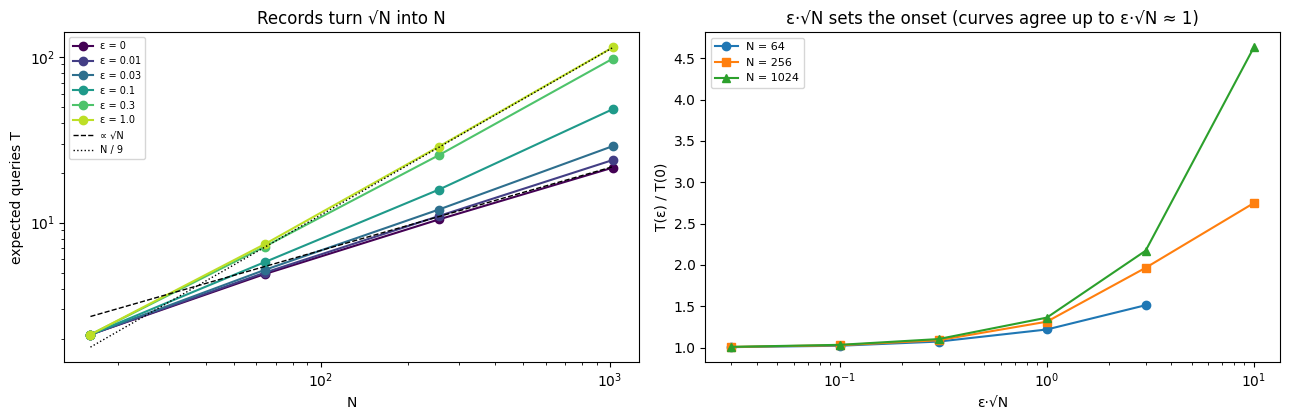

In [5]:
def search_with_records(N, eps, w=0):
    s = np.full(N, 1 / np.sqrt(N))
    o = np.ones(N); o[w] = -1
    rho = np.outer(s, s)
    best, P, k = np.inf, [], 0
    while k < best and k < 50 * N:
        k += 1
        rho = rho * np.outer(o, o)                          # oracle
        Dr = 2 * np.outer(s, s @ rho) - rho                 # diffusion, left
        rho = 2 * np.outer(Dr @ s, s) - Dr                  # diffusion, right
        d = np.diag(rho).copy()
        rho = (1 - eps) * rho; rho[np.diag_indices(N)] = d  # record
        P.append(rho[w, w])
        best = min(best, k / rho[w, w])
    return best, np.array(P)


_, P1 = search_with_records(64, 1.0)
print('full records, N = 64:  N·P_w after each query =', np.round(64 * P1[:6], 2))

Ns = [16, 64, 256, 1024]
epss = [0, 0.01, 0.03, 0.1, 0.3, 1.0]
T = {(e, N): search_with_records(N, e)[0] for e in epss for N in Ns}
for e in epss:
    alpha = np.polyfit(np.log(Ns[-2:]), np.log([T[(e, N)] for N in Ns[-2:]]), 1)[0]
    print(f'ε = {e:<5}  T = ' + '  '.join(f'{T[(e, N)]:7.1f}' for N in Ns) + f'   exponent (256→1024) = {alpha:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(epss)))
for e, col in zip(epss, cmap):
    axes[0].loglog(Ns, [T[(e, N)] for N in Ns], 'o-', color=col, label=f'ε = {e}')
Na = np.array(Ns)
axes[0].loglog(Na, 0.68 * np.sqrt(Na), 'k--', lw=1, label='∝ √N')
axes[0].loglog(Na, Na / 9, 'k:', lw=1, label='N / 9')
axes[0].set_xlabel('N'); axes[0].set_ylabel('expected queries T')
axes[0].set_title('Records turn √N into N')
axes[0].legend(fontsize=7)

xs = [0.03, 0.1, 0.3, 1, 3, 10]
for N, mk in zip([64, 256, 1024], ['o', 's', '^']):
    T0 = search_with_records(N, 0)[0]
    pts = [(x, search_with_records(N, x / np.sqrt(N))[0] / T0) for x in xs if x / np.sqrt(N) <= 1]
    axes[1].semilogx(*zip(*pts), mk + '-', label=f'N = {N}')
axes[1].set_xlabel('ε·√N'); axes[1].set_ylabel('T(ε) / T(0)')
axes[1].set_title('ε·√N sets the onset (curves agree up to ε·√N ≈ 1)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

<!-- expansion:09:howto-sec4 -->
### 🧭 How to use this cell / what to look at

**What it computes.** `search_with_records` pushes ρ through oracle, diffusion and a record of strength ε, query after query, keeping
the best restart cost $T = \min_k k/P_w(k)$ (run $k$ queries, look, start over on failure). It sweeps six ε and four $N$.

**What to look at.**
- Full records, $N = 64$: $N P_w$ = `8.63 8.15 7.71 7.29 6.89 6.52`. The first query helps; every later one hurts.
- $\varepsilon = 0$: `2.1 4.9 10.5 21.5`, exponent `0.52` (√N). $\varepsilon = 1$: `114.1` at $N = 1024$, exponent `0.99` (about $N/9$).
- At $N = 1024$ ($\sqrt N = 32$): ε = 0.01 (ε√N ≈ 0.3) costs `23.9` vs `21.5`; ε = 0.03 (≈ 1) `29.0`; ε = 0.1 (≈ 3) `48.4`. Damage starts near ε√N ≈ 1.
- $N = 16$ is `2.1` for every ε: the first query acts before any record, and at this size "one query, then restart" is already optimal.
- At $\varepsilon = 0$, $N = 1024$, the best stopping point is $k = 18$ ($P_w = \sin^2(37\theta) = 0.84$), not $k^* = 25$: with restarts it
  pays to stop early, and the expected cost `21.5` is below the 25 queries of one full run.
- Right plot: three $N$ against ε√N coincide up to about 1, the evidence for the ε√N rule.

**Try this.** Add `0.001` to `epss`. Prediction (spike note): $T \approx 21.7$ at $N = 1024$, exponent still 0.52.


### 📖 In depth: why records cost √N, and why with full records a longer search does worse

- **The ε·√N rule.** After each record, a fraction ε of the coherent search state is turned into a classical mixture over indices.
  That mixture carries no phase, so the oracle cannot act on it (section 1). The coherent fraction after $k$ queries is about
  $(1-\varepsilon)^k$, and the search needs $k \approx \tfrac{\pi}{4}\sqrt N$, so, as a scaling estimate (the table above checks it),
  the speedup survives only if $\varepsilon\sqrt N \lesssim 1$.
  Larger databases need quieter searches: $N = 10^6$ needs $\varepsilon \lesssim 10^{-3}$ per query. This scale is known:
  Shenvi, Brown & Whaley (2003) show that a random oracle phase error must shrink as $O(N^{-1/4})$ (§II), i.e. a per-query coherence
  loss of order $N^{-1/2}$, the same scale as here, for a different noise model.
- **Full records.** Every query is then a division event, and the step is $\Gamma(D)\Gamma(O) = \Gamma(D)$: the oracle has dropped out.
  $\Gamma(D)$ is a doubly stochastic mixing matrix, so it drives any distribution toward uniform. After the first (coherent) query lifts
  $P_w$ to about $9/N$, every later query pulls it back down. Searching longer is strictly worse, so the best strategy is one query and restart,
  about $N/9$ queries in total: classical scaling.
- **Connection to notebook 08.** Each record is a phase damping channel, CP-divisible at every strength. By the textbook's standard,
  the noisy search is perfectly Markovian at every ε. Each record shortens the indivisible stretch to about $1/\varepsilon$ queries; once that is
  shorter than the ~√N queries the search needs, the speedup is gone. That does not require Γ to become divisible: for small ε it stays
  indivisible, and only ε = 1 guarantees divisibility. (Started from configurations at $N = 16$ and 64, $\Gamma(t\leftarrow t') =
  \Gamma(t\leftarrow 0)\,\Gamma(t'\leftarrow 0)^{-1}$ is already stochastic for every tested pair of query times, up to 6 queries, once $\varepsilon \ge 0.7$.)

<!-- expansion:09:deriv-markov -->
### 🧮 Worked derivation: full records, the $1 - 4/N$ decay, and $N/9$

$\Gamma(D)$ has diagonal $(1-2/N)^2$ and off-diagonals $4/N^2$; rows and columns sum to 1 (doubly stochastic).

1. **First query** acts on the coherent $|s\rangle$: $P_w = \sin^2(3\theta) \approx 9/N$. For $N = 64$, $N P_w = 8.63$, the first printed value.
2. **Every later query** is the Markov step $\Gamma(D)\Gamma(O) = \Gamma(D)$:
   $$P_w' = (1-\tfrac2N)^2 P_w + \tfrac{4}{N^2}(1 - P_w) \quad\Longrightarrow\quad P_w' - \tfrac1N = \big(1 - \tfrac4N\big)\big(P_w - \tfrac1N\big).$$
3. **Check.** $N = 64$: $1 + 0.9375 \times 7.63 = 8.15$, then $1 + 0.9375 \times 7.15 = 7.71$, the printed sequence.
4. **Best strategy.** $P_w$ only falls after query 1, so stop and restart: $T = 1/P_w(1) = 1/\sin^2(3\theta)$, which is 28.7 at $N = 256$
   and 114.1 at $N = 1024$, the printed values. For large $N$ this is about $N/9$ (28.4 and 113.8).
   A constant factor from one coherent query; no √N.


<!-- expansion:09:deriv-eps -->
### 🧮 Worked derivation: where ε√N ≈ 1 comes from

- **The record is phase damping.** N&C §8.3.6: "the loss of quantum information without loss of energy". Their qubit model multiplies the
  off-diagonals by $e^{-\lambda}$ and leaves the diagonal alone (eq. 8.125). The code's record is the same in the index basis, with $1 - \varepsilon = e^{-\lambda}$.
- **What survives.** After $k$ records the off-diagonals carry $(1-\varepsilon)^k$. Grover's progress lives in those entries (sections 1 and 3).
- **Plug in the run length.** $k \approx \tfrac{\pi}{4}\sqrt N$ gives $(1-\varepsilon)^{\pi\sqrt N/4} \approx e^{-\pi\varepsilon\sqrt N/4}$: near 1 for $\varepsilon\sqrt N \ll 1$, tiny for $\varepsilon\sqrt N \gg 1$.
- **Limits.** A scaling estimate, not a formula for $T$: restarts allow early stopping, and the collapse onto ε√N is approximate (slow residual drift with $N$, see the Summary caveats).


<!-- expansion:09:recap-sec4 -->
### 📝 Recap: section 4

- Records multiply the coherences by $1-\varepsilon$ per query; once $\varepsilon\sqrt N \gtrsim 1$ the cost exponent moves from 0.5 toward 1.
- Full records leave the $w$-blind chain $\Gamma(D)$: $P_w$ decays toward $1/N$, best cost about $N/9$.
- The noise is CP-divisible at every strength (notebook 08), and for small ε Γ stays indivisible (only ε = 1 guarantees divisibility; started from configurations at $N = 16$ and 64, ε ≥ 0.7 is already divisible at every tested query time); what kills the speedup is that each record cuts the coherent stretch to about $1/\varepsilon$ queries, shorter than the ~√N the search needs. Search reading: log every intermediate ranking in a way that collapses it, and you are back to guess-and-check.


## 5. Continuous-Time Search and Its Speed Limit

Farhi–Gutmann search: $H = |w\rangle\langle w| + |s\rangle\langle s|$ (frequency units), started in $|s\rangle$; it reaches $|w\rangle$ at $T = \pi\sqrt N/2$.
Read the agility $\nu_j = \sqrt{-\tfrac12\ddot\Gamma_{jj}(0)}$ off Γ alone, as in notebook 07, and compare $T$ with

$$T \;\ge\; \frac{\arccos(1/\sqrt N)}{\nu}$$

(start and target overlap by $1/\sqrt N$), and with the naive form $T\nu \ge \pi/2$. The bound rests on the column moving no faster than ν.
That holds for this Hamiltonian; the end of this section shows a diagonal term that leaves ν unchanged but lets the column move faster than ν.

N =     4:  T =   3.141   ν from Γ = 0.43301…0.43301   max column speed / ν = 1.0000   Tν/(π/2) = 0.8659   T / (arccos(1/√N)/ν) = 1.2989
N =    16:  T =   6.283   ν from Γ = 0.24206…0.24206   max column speed / ν = 1.0000   Tν/(π/2) = 0.9681   T / (arccos(1/√N)/ν) = 1.1537
N =    64:  T =  12.565   ν from Γ = 0.12402…0.12402   max column speed / ν = 1.0000   Tν/(π/2) = 0.9921   T / (arccos(1/√N)/ν) = 1.0781
N =   256:  T =  25.130   ν from Γ = 0.06238…0.06238   max column speed / ν = 1.0000   Tν/(π/2) = 0.9979   T / (arccos(1/√N)/ν) = 1.0393


N =  1024:  T =  50.260   ν from Γ = 0.03123…0.03123   max column speed / ν = 1.0000   Tν/(π/2) = 0.9994   T / (arccos(1/√N)/ν) = 1.0197


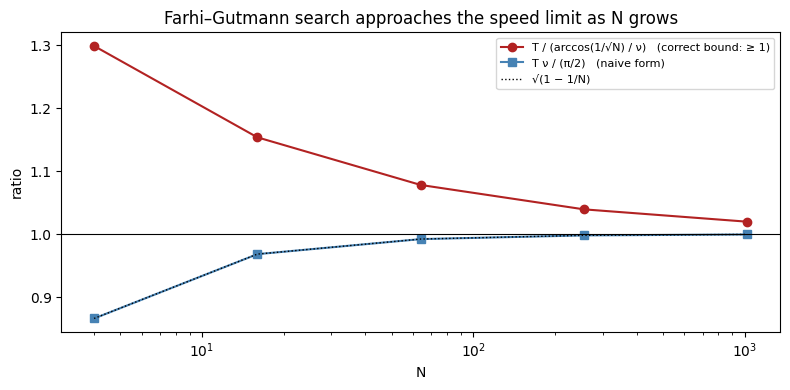

In [6]:
rows = []
for N in [4, 16, 64, 256, 1024]:
    x = 1 / np.sqrt(N)
    s = np.full(N, x); e_w = np.zeros(N); e_w[0] = 1
    H = np.outer(e_w, e_w) + np.outer(s, s)
    ev, V = np.linalg.eigh(H)
    ts = np.linspace(0, 1.2 * np.pi / (2 * x), 4001)
    P = np.abs(V @ (np.exp(-1j * np.outer(ev, ts)) * (V.T @ s)[:, None])) ** 2
    T_hit = ts[np.argmax(P[0])]
    h = 1e-4
    nu = np.sqrt(np.clip(-(np.diag(Gam(expm(-1j * H * h))) - 1) / h ** 2, 0, None))
    dP = np.gradient(P, ts, axis=1)
    with np.errstate(divide='ignore', invalid='ignore'):
        speed = 0.5 * np.sqrt(np.where(P > 1e-14, dP ** 2 / P, 0).sum(axis=0))
    m = ts <= T_hit
    rows.append((N, T_hit, nu.min(), nu.max(), speed[m][1:-1].max() / nu[1],
                 T_hit * nu[1] / (np.pi / 2), T_hit / (np.arccos(x) / nu[1])))
    print(f'N = {N:5d}:  T = {T_hit:7.3f}   ν from Γ = {nu.min():.5f}…{nu.max():.5f}'
          f'   max column speed / ν = {rows[-1][4]:.4f}'
          f'   Tν/(π/2) = {rows[-1][5]:.4f}   T / (arccos(1/√N)/ν) = {rows[-1][6]:.4f}')

Nr = np.array([r[0] for r in rows])
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(Nr, [r[6] for r in rows], 'o-', color='firebrick', label='T / (arccos(1/√N) / ν)   (correct bound: ≥ 1)')
ax.semilogx(Nr, [r[5] for r in rows], 's-', color='steelblue', label='T ν / (π/2)   (naive form)')
ax.semilogx(Nr, np.sqrt(1 - 1 / Nr), 'k:', lw=1, label='√(1 − 1/N)')
ax.axhline(1, color='black', lw=0.8)
ax.set_xlabel('N'); ax.set_ylabel('ratio')
ax.set_title('Farhi–Gutmann search approaches the speed limit as N grows')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

<!-- expansion:09:howto-sec5 -->
### 🧭 How to use this cell / what to look at

**What it computes.** For $N = 4$ to $1024$: exact Farhi–Gutmann evolution from $|s\rangle$, the hitting time $T$, the agility ν of every
configuration, the column speed $\tfrac12\sqrt{\sum_i \dot p_i^2/p_i}$, and two ratios.

**What to look at.**
- `T` = 3.141, 6.283, 12.565, 25.130, 50.260: $\pi\sqrt N/2$ up to the time grid.
- `ν from Γ`: min equals max, so every configuration has the same agility (`0.24206` at $N = 16$).
- `max column speed / ν = 1.0000`: for this Hamiltonian the column reaches, never exceeds, ν. (A diagonal term changes that; see the end of the section.)
- `Tν/(π/2)` below 1 (0.8659 at $N = 4$): the naive bound "failing".
- `T / (arccos(1/√N)/ν)`: 1.2989, 1.1537, 1.0781, 1.0393, 1.0197. The correct bound holds and tightens.

**Note.** The printout gives the *maximum* speed. At $t = 0$ the speed is zero ($P_w(t) = \sin^2(t/\sqrt N) + \cos^2(t/\sqrt N)/N$ has zero slope there),
and it rises to ν. That slow start is where the gap above the bound comes from.

**Try this.** Multiply `H` by 2. Prediction: $T$ halves, ν doubles, both ratios unchanged up to the time grid (the grid is not
rescaled, so the last digit can move: 1.0197 becomes 1.0200 at $N = 1024$). The bound is about time at a given energy scale.


### 📖 In depth: the speed limit, and why the naive form fails

Notebook 07's inequality 3, $\Gamma_{jj}(t) \ge \cos^2(\nu_j t)$, is about leaving a **configuration**. Search starts from the prepared $|s\rangle$, which is not a
configuration, and its target $e_w$ is not orthogonal to the start: the angle between them is $\arccos(1/\sqrt N)$, a little less than $\pi/2$.
If the column speed stays $\le \nu$, the sphere argument of notebook 07 gives $T \ge \arccos(1/\sqrt N)/\nu$. For this Hamiltonian it does
(the printed ratio never exceeds 1); in general it need not, as the cell after this one shows.

- The naive $T\nu \ge \pi/2$ is "violated" by exactly $\sqrt{1 - 1/N}$ only because it assumes a right angle that is not there.
- The correct bound is approached: the gap is about $(2/\pi)/\sqrt N$, 2% at $N = 1024$.
- The column's speed starts at 0 (every entry of the uniform column has zero slope at $t = 0$) and rises to the maximum $\nu$
  (the printed ratio 1.0000 is its peak). So reading the index captures all of the quantum Fisher information only at that peak,
  where the borrowed Braunstein–Caves step of notebook 07 is saturated. The slow start is why $T$ sits above the bound (2% at $N = 1024$).
- ν read from any single configuration equals the energy spread of $|s\rangle$. That is a property of this symmetric Hamiltonian,
  not a general theorem.

This bound counts **time at a fixed energy scale**, not queries. Converting time into oracle calls depends on how the
Hamiltonian is simulated (N&C §6.2); the query bound itself is the subject of the 📖 cell "can Γ alone prove the √N limit?" below.

### The limit belongs to this Hamiltonian, not to Γ

"Column speed ≤ ν" is notebook 07's inequality for a start in a configuration. Search starts in $|s\rangle$, and there the inequality holds only
because the Farhi–Gutmann Hamiltonian is so symmetric. Add a diagonal term, $+a$ on odd unmarked indices and $-a$ on even ones. The agility ν read off Γ
does not change, because $\nu_j^2 = \sum_{i\ne j}|H_{ij}|^2$ involves only off-diagonal entries. The column's speed does.

In [7]:
N = 16
s = np.full(N, 1 / np.sqrt(N)); e_w = np.zeros(N); e_w[0] = 1
ts = np.linspace(0, 8, 8001)
for a in [0.0, 0.5, 1.0, 2.0]:
    pert = np.zeros(N); pert[1::2] = a; pert[2::2] = -a          # ±a on the unmarked indices
    H = np.outer(e_w, e_w) + np.outer(s, s) + np.diag(pert)
    h = 1e-4
    nu = np.sqrt(np.clip(-(np.diag(Gam(expm(-1j * H * h))) - 1) / h ** 2, 0, None)).max()
    ev, V = np.linalg.eigh(H)
    P = np.abs(V @ (np.exp(-1j * np.outer(ev, ts)) * (V.T @ s)[:, None])) ** 2
    angle = np.arccos(np.clip(np.sqrt(P[:, 0]) @ np.sqrt(P), -1, 1))      # Bhattacharyya angle from the start
    dP = np.gradient(P, ts, axis=1)
    with np.errstate(divide='ignore', invalid='ignore'):
        speed = 0.5 * np.sqrt(np.where(P > 1e-14, dP ** 2 / P, 0).sum(axis=0))
    ratio = angle[1:] / (nu * ts[1:])
    i = np.argmax(ratio)
    print(f'a = {a}:  ν from Γ = {nu:.5f}   max column speed / ν = {speed.max() / nu:.4f}'
          f'   max angle travelled / (ν t) = {ratio[i]:.4f} (at t = {ts[i + 1]:.2f})')

a = 0.0:  ν from Γ = 0.24206   max column speed / ν = 1.0000   max angle travelled / (ν t) = 0.8667 (at t = 6.28)
a = 0.5:  ν from Γ = 0.24206   max column speed / ν = 2.0257   max angle travelled / (ν t) = 1.4289 (at t = 1.99)
a = 1.0:  ν from Γ = 0.24206   max column speed / ν = 2.0494   max angle travelled / (ν t) = 1.4625 (at t = 1.11)
a = 2.0:  ν from Γ = 0.24206   max column speed / ν = 2.0645   max angle travelled / (ν t) = 1.4760 (at t = 0.58)


### 📖 In depth: why a diagonal term beats ν

- **What the printout shows.** At $a = 0$ the column never moves faster than ν. With $a > 0$, ν is unchanged, yet the column reaches about twice
  that speed, and the angle travelled from the start runs ahead of $\nu t$ by roughly 45%. The bound $T \ge \arccos(1/\sqrt N)/\nu$ rests on exactly
  that inequality, so it is a property of the Farhi–Gutmann Hamiltonian, not a law about every process with the same Γ-agility.
- **Why.** The honest limit on how fast the index distribution can move is the energy spread of the *current state* (the quantum Fisher
  information, as in notebook 07). For a start in a configuration $j$ that spread is $\nu_j$, which Γ supplies. For a start in $|s\rangle$ it is the
  spread of $|s\rangle$, which Γ does not supply. The diagonal term raises it to about $a$ while leaving every $\nu_j$ alone. In the symmetric case the
  two coincide, which is why section 5's bound held.
- **It is not special to this example.** Random 6-level Hamiltonians started in random superpositions exceed $\max_j \nu_j$ in 24 of 300 runs,
  by up to a factor 1.12 (recheck of 2026-10-29).

<!-- expansion:09:papers-nc-fg -->
### 📚 From the papers: search as a Hamiltonian (N&C §6.2)

N&C "derive" Grover by guessing a Hamiltonian, then simulating it.

- $H = |x\rangle\langle x| + |\psi\rangle\langle\psi|$ (eq. 6.18); in the plane, $H = I + \alpha(\beta X + \alpha Z)$ (eq. 6.21) with $\alpha = \langle x|\psi\rangle$.
- The state is $\cos(\alpha t)|\psi\rangle - i\sin(\alpha t)|x\rangle$ (eq. 6.23), so "observation of the system at time $t = \pi/2\alpha$ yields the result $|x\rangle$ with probability one".
- Uniform $|\psi\rangle$ (eq. 6.24) gives $\alpha = 1/\sqrt N$ for every $x$, so the time $\pi\sqrt N/2$ "does not depend on knowing the value of $x$".
- Simulating $H$ in short alternating steps costs oracle calls: first-order simulation gives $O(N)$, "no better than the classical solution"; the next order gives $O(N^{3/4})$.
- Chapter notes (p. 276): the Hamiltonian "was first investigated by Farhi and Gutmann" [FG98].

Hence section 5's bound counts *time*, not queries: converting time to oracle calls depends on the simulation.


<!-- expansion:09:deriv-fg -->
### 🧮 Worked derivation: the two-level reduction, $T = \pi\sqrt N/2$, and the ratios

1. **Two levels.** $H$ maps the plane of $|w\rangle$ and $|s\rangle$ into itself and annihilates everything orthogonal to it. In the plane its
   eigenvalues are $1 \pm \alpha$, $\alpha = 1/\sqrt N$.
2. **Hitting time.** From eq. 6.23, $P_w(t) = |\alpha\cos(\alpha t) - i\sin(\alpha t)|^2 = \sin^2(\alpha t) + \cos^2(\alpha t)/N$, first 1 at $\alpha t = \pi/2$: $T = \pi\sqrt N/2$ ($2\pi = 6.283$ at $N = 16$).
3. **Agility.** $\nu_j$ is the energy spread in configuration $j$. Unmarked $j$: $H|j\rangle = |s\rangle/\sqrt N$, so $\langle H\rangle = \langle H^2\rangle = 1/N$ and
   $\nu^2 = 1/N - 1/N^2$; the marked index and $|s\rangle$ give the same. $N = 16$: $\nu = 0.24206$, as printed.
4. **Naive ratio.** $T\nu/(\pi/2) = \sqrt{1 - 1/N}$: $0.8660$ at $N = 4$, the dotted curve.
5. **Correct ratio.** $\arccos(1/\sqrt N) \approx \pi/2 - 1/\sqrt N$, so
   $$\frac{T}{\arccos(1/\sqrt N)/\nu} \approx 1 + \frac{2}{\pi\sqrt N},$$
   $1.0199$ at $N = 1024$. The exact ratio $(\pi/2)\sqrt{1 - 1/N}/\arccos(1/\sqrt N)$ is $1.0198$; the printed $1.0197$ is a hair lower
   because the code reads $T$ off a time grid (50.260 against the exact 50.265).


### 📖 In depth: can Γ alone prove the √N limit?

Short answer: **not by the standard route.** The standard hybrid-argument proof cannot be carried out in Γ alone: like notebook 07,
it comes down to exactly one borrowed step, the unitary dilation. Whether some other Γ-only proof exists is open.
Details and test cases are in `notes/gamma-only-query-bound-spike-2026-10-23.md`.

Compare the run with item $w$ marked to the run with the oracle removed, using the Hellinger distance between their
configuration columns, $h = \|\sqrt{p^w} - \sqrt{p^\varnothing}\|$.

- **Statable in Γ.** $h(p^w_k, p^\varnothing_k) \le 2\sum_{j\le k}\sqrt{p^\varnothing_j(w)}$, where $p^\varnothing_j(w)$ is the no-oracle run's probability of being at $w$
  before query $j$. It held in all 8,960 checks (Grover and random algorithms, both oracle types); Grover meets it exactly.
- **The counting step is Γ-only.** Summing over $w$ and using only $\sum_w p^\varnothing_j(w) = 1$ (Cauchy–Schwarz) gives $k \ge c\sqrt N$.
- **Queries are Γ-boundable.** A phase oracle moves no column; a bit oracle moves $h$ by at most $\sqrt2\sqrt{p(w)}$ (permutation invariance plus the
  triangle inequality).
- **The query-free steps are not.** The same step applied to both runs *increased* $h$ in about half of all cases: in Grover, $h$ goes from
  0 right after the first query to $2/\sqrt N$ after the next $D$ (0.25 at $N = 64$). Under a stochastic matrix $h$ can only shrink, so a Γ-only proof would need
  exactly the property that indivisible steps lack (notebook 07: indivisible processes recover distinguishability).
- **Γ of the step does not fix the growth.** 20,000 unitaries with exactly $\Gamma(V) = \Gamma(D)$, applied to the same post-query pair, gave $h$ from
  0.037 to 0.167; $D$ itself gives 0.25, which equals the Hilbert distance, the quantity the standard proof conserves.

**Irony.** With a division event before every query the process is divisible and the Γ-only proof goes through, but then a
phase-oracle search cannot progress at all (its step is the $w$-blind $\Gamma(D)$; section 4's runs gain only from their first,
still-coherent query) and a classical (bit-oracle) search gets a valid but loose √N bound, against a true cost of order $N$.
The Γ-only proof works exactly for the processes that cannot reach the bound.

<!-- expansion:09:papers-nc-optimality -->
### 📚 From the papers: why √N is optimal (N&C §6.6)

"No quantum algorithm can perform this task using fewer than $\Omega(\sqrt N)$ accesses to the search oracle."

- **Two runs**: $|\psi^x_k\rangle = U_kO_x\cdots U_1O_x|\psi\rangle$ with the oracle (eq. 6.38), $|\psi_k\rangle = U_k\cdots U_1|\psi\rangle$ without (eq. 6.39).
- **Deviation** $D_k \equiv \sum_x\|\psi^x_k - \psi_k\|^2$ (eq. 6.40), "a measure of the deviation after $k$ steps caused by the oracle".
- **Upper bound**: $D_k \le 4k^2$ by induction (eqs. 6.41–6.46).
- **Lower bound**: success $\ge 1/2$ for every $x$ forces $D_k \ge cN$, $c$ below about 0.42 (eqs. 6.47–6.51, Exercise 6.15). So $k \ge \sqrt{cN/4}$ (eq. 6.52).
- **Attribution** (chapter notes, p. 276): Bennett, Bernstein, Brassard and Vazirani; presented following Boyer, Brassard, Høyer and Tapp;
  Zalka showed the algorithm "is, asymptotically, exactly optimal".


<!-- expansion:09:deriv-bbbv -->
### 🧮 Worked derivation: the hybrid argument in plain steps, and where Γ gets stuck

**Hilbert-space version, per marked item $x$.**
1. Between queries both runs get the same unitary, which preserves $\|\psi^x - \psi\|$.
2. A query adds at most $\|(O_x - I)\psi_j\| = 2|\langle x|\psi_j\rangle|$ (triangle inequality).
3. So $\|\psi^x_k - \psi_k\| \le 2\sum_{j<k}|\langle x|\psi_j\rangle|$: runs diverge only where the oracle-free run has amplitude on $x$.
4. Cauchy–Schwarz: $\sum_x|\langle x|\psi_j\rangle| \le \sqrt N$, so the total divergence over all $x$ is at most $2k\sqrt N$.
5. Finding $x$ reliably needs divergence of order 1 for most of the $N$ items: $2k\sqrt N \gtrsim N$, so $k \gtrsim \sqrt N$.

**In Γ.** Entrywise $\big||\psi_i| - |\phi_i|\big| \le |\psi_i - \phi_i|$, so Hellinger distance ≤ Hilbert distance. Here $\psi_j$ is the oracle-free state
just before query $j+1$, so $|\langle w|\psi_j\rangle|^2$ is the probability the 📖 cell calls $p^\varnothing_{j+1}(w)$ (it numbers by query, $j = 1,\dots,k$).
With step 3 this gives the 📖 cell's $h \le 2\sum_{j\le k}\sqrt{p^\varnothing_j(w)}$. Steps 4–5 use only $\sum_w p(w) = 1$: pure Γ.

**Where it breaks.** Step 1. A stochastic matrix never increases $h$, but across a time where the process is indivisible no stochastic map of the current columns gives the next ones:
identical columns can come out different. The standard proof needs a distance the query-free steps conserve, and the only one on hand is the Hilbert norm: the dilation.


<!-- expansion:09:recap-sec5 -->
### 📝 Recap: section 5 and the query-bound spike

- Farhi–Gutmann search hits $|w\rangle$ at $T = \pi\sqrt N/2$; ν from Γ is $\sqrt{1/N - 1/N^2}$ for every configuration.
- For this Hamiltonian $T \ge \arccos(1/\sqrt N)/\nu$ holds and tightens as $1 + (2/\pi)/\sqrt N$; the naive $T\nu \ge \pi/2$ wrongly assumes a configuration start and an orthogonal target.
- It is not a Γ-only law: a diagonal term leaves ν unchanged and lets the column move about twice as fast as ν.
- The query bound can be stated and counted in Γ; in the standard (hybrid-argument) proof, the step-by-step part needs the unitary dilation. Whether another Γ-only proof exists is open.


### 🔭 Looking ahead

**Prior work (literature check of 2026-10-29).**
- **Phase oracle invisible to Γ:** a restatement. A phase changes no probability; that is standard quantum mechanics in Γ language.
- **Bare start:** known. Biham et al. (1999), Phys. Rev. A 60, 2742 (quant-ph/9807027), treat Grover's search from an arbitrary initial
  amplitude distribution, which includes a single configuration.
- **Geodesic:** known. Miyake and Wadati (2001), "Geometric strategy for the optimal quantum search", Phys. Rev. A 64, 042317
  (quant-ph/0109109); also Alvarez and Gómez (1999), quant-ph/9910115 (a preprint).
- **Records kill the speedup:** known. Shenvi, Brown & Whaley (2003), Phys. Rev. A 68, 052313, §II: a random oracle phase error must shrink as
  $O(N^{-1/4})$, i.e. a per-query coherence loss of order $N^{-1/2}$, or the speedup is lost (a different noise model from this notebook's). Also Reitzner and Hillery (arXiv:1712.06558) and Regev and Schiff (arXiv:1202.1027). Earlier noise studies:
  Azuma (2002), Phys. Rev. A 65, 042311; Pablo-Norman & Ruiz-Altaba (quant-ph/9903070); Long, Li, Zhang & Tu (2000), "Dominant gate
  imperfection in Grover's quantum search algorithm", Phys. Rev. A 61, 042305. Search under repeated monitoring is also studied as first detection in
  monitored quantum walks: Friedman, Kessler and Barkai (2017), Phys. Rev. E 95, 032141.
- **Speed limit:** known. $T \ge \arccos(1/\sqrt N)/\nu$ is the Mandelstam–Tamm bound (non-orthogonal form) for the start $|s\rangle$; ν can
  stand in for the energy spread of $|s\rangle$ only because the two are equal for the Farhi–Gutmann Hamiltonian (end of section 5).
- **Γ-only query bound:** a restatement. It is a weaker form of Bennett–Bernstein–Brassard–Vazirani (1997), SIAM J. Comput. 26, 1510,
  via Hellinger distance ≤ Hilbert distance. Related optimality results: Boyer, Brassard, Høyer & Tapp (1998), Fortschr. Phys. 46, 493;
  Zalka (1999), Phys. Rev. A 60, 2746; the Ambainis adversary method (quant-ph/0002066). Farhi & Gutmann (1998), Phys. Rev. A 57, 2403,
  first studied the Hamiltonian of section 5.
- **Barandes's later papers do not treat algorithms.** arXiv:2512.18105 (Barandes, Hasan and Kagan) is about the CHSH game, Tsirelson's bound
  and causal locality; arXiv:2608.04354 is about the Born representation and unistochastic theorems.

What remains of this notebook, beyond the restatements: a worked Grover instance of Barandes's general claim (Paper 2 §6, p. 29: what gives
quantum computers their possible advantage is "their access to dynamical laws that are indivisible"), with query information travelling through
indivisibility and the fully recorded search doing worse the longer it runs.

**Open.**
- **Hidden-variable search and indivisibility.** Aaronson (quant-ph/0408035, quant-ph/0408119) maps unitaries to stochastic matrices and shows
  that being able to sample a hidden-variable *history* would allow search in $O(N^{1/3})$ queries, faster than Grover. An indivisible process
  has no joint law over multiple times. Does that exactly block the $N^{1/3}$ speedup? This is the strongest search-centric question the check
  turned up; no treatment of it was found in our searches.
- **A Γ-only query lower bound: answered, no** (see the 📖 cell above and `notes/gamma-only-query-bound-spike-2026-10-23.md`).
  Can a weaker premise than full unitarity, such as a hidden distance that dominates the Hellinger distance and is conserved by the
  query-free steps, close the gap? Probably equivalent to the dilation; unproven.
- **The residual drift** in the ε√N collapse at large ε√N.
- **Multiple marked items, amplitude amplification**, and records in a basis other than the index basis.

## Summary

- **A phase oracle is invisible to Γ.** $\Gamma(O) = I$ and $\Gamma(DO) = \Gamma(D)$. Started from a configuration, the marked item first appears in
  $\Gamma((DO)^2)$, which differs from $\Gamma(DO)^2$ (with the Walsh–Hadamard step first it appears after one query, since no stochastic step maps
  $\Gamma(W)$ to $\Gamma(DOW)$): query information reaches the configurations only through indivisibility. A bit oracle (ancilla in the configuration)
  is a Γ-visible permutation; what Γ cannot see, in either encoding, is what the query-free steps do with the phases.
- **Preparation is essential.** From a bare configuration the queries never lift $\Gamma_{w\leftarrow 0}$ above $1/(N-1)$ ($1.01/N$ at $N = 64$), while a classical
  searcher has found $w$ with probability $k/N$ after $k$ queries: bare-start search is worse than classical. The query-free Walsh–Hadamard step makes the speedup possible.
- **Geodesic.** The probability column moves along the great circle from uniform to $e_w$, at exactly $2\theta = 2\arcsin(1/\sqrt N)$ per query (N&C's rotation angle θ),
  for as long as $(2k+1)\theta \le \pi/2$.
- **Records.** Phase damping of strength ε after each query erodes the speedup once $\varepsilon\sqrt N \gtrsim 1$; the scaling exponent goes from 0.5 to 1.
  With full records the step is $\Gamma(D)$, independent of $w$, and the success probability decays back toward $1/N$.
- **Speed limit, for this Hamiltonian.** Farhi–Gutmann search moves the column along a geodesic, reaching speed ν at its peak (it starts from rest), and its hitting time approaches
  $\arccos(1/\sqrt N)/\nu$ with ν read off Γ (2% above it at $N = 1024$). The naive form $T\nu \ge \pi/2$ does not apply because the start
  is not a configuration and the target is not orthogonal to it. The bound is not a Γ-only law: a diagonal term leaves ν unchanged but lets the column
  move about twice as fast as ν (2.05 ν at $a = 1$, $N = 16$).

Caveats: a single marked item, synthetic noise in the index basis only, cost measured with restarts, and the
$\varepsilon\sqrt N$ collapse is approximate (a slow residual drift with $N$ remains).

Prior work: the invisibility of a phase oracle restates standard quantum mechanics in Γ language. Search from an arbitrary start, including a
bare configuration, is Biham et al. (1999); Grover's search as a geodesic is Miyake and Wadati (2001, Phys. Rev. A 64, 042317) and
Alvarez and Gómez (1999, preprint). Shenvi, Brown & Whaley (2003) show that a random oracle phase error must shrink as $O(N^{-1/4})$ (§II),
i.e. a per-query coherence loss of order $N^{-1/2}$: the same scale as the $\varepsilon\sqrt N \lesssim 1$ found here, for a different noise model.
The arccos bound is the Mandelstam–Tamm bound (non-orthogonal form) for the start $|s\rangle$; ν can stand in for the energy spread of $|s\rangle$
only because the two are equal for the Farhi–Gutmann Hamiltonian.

### 📖 In depth: the one-paragraph version

A Grover query writes the answer as a phase, and Γ cannot see phases, so a single query changes no probability. The
answer reaches the probabilities only through interference between successive queries: through indivisibility. Record the
index after each query and the interference is gone, the oracle drops out of the process, and the search decays back to guessing.
Leave it unrecorded and the probability column rolls along the shortest path on the probability sphere; in Farhi–Gutmann's continuous
time it reaches, at its peak, the speed ν read off Γ. That ν is a limit for this Hamiltonian only: a diagonal term lets the column go faster.

<!-- expansion:09:final-recap -->
### 📝 Notebook recap and where to go next

**In one breath.** The query hides the answer in a phase; two queries and indivisibility bring it into Γ; a query-free preparation
makes it usable; the column then rolls along a great circle at $2\theta$ per query; records at strength $\varepsilon \gtrsim 1/\sqrt N$ undo it;
the Farhi–Gutmann continuous version reaches speed ν at its peak and its hitting time approaches $\arccos(1/\sqrt N)/\nu$, a bound that holds for that Hamiltonian but not in general; and the standard proof that nothing faster exists needs one Hilbert-space step.

**Where to go next.** The working material is in `notes/`:
- `grover-as-isp-spike-2026-10-23.md`: the original spike, the full ε table (including ε = 0.001) and the unresolved residual drift.
- `gamma-only-query-bound-spike-2026-10-23.md`: the Hellinger tests, the 20,000-unitary experiment, the "hidden conserved distance" question.
- `margolus-levitin-gamma-spike-2026-10-23.md`: why Γ cannot tell $H$ from its time-reversed twin, and why Margolus–Levitin in its orthogonality form does not apply to search.

**Open questions worth a notebook.**
- A Γ-native query bound from a weaker premise than full unitarity.
- Multiple marked items and amplitude amplification: does the geodesic picture survive?
- Records in a basis other than the index basis: is any basis harmless?
- Aaronson's hidden-variable search: sampling a hidden-variable history allows $O(N^{1/3})$ queries. Does indivisibility, with no joint law over multiple times, block it?
